In [ ]:

# Quantum ML for Alzheimer's Disease Detection Using MRI Data

# Project Overview

# Alzheimer's disease is a progressive neurological disorder that affects memory, thinking, and other cognitive functions. 
# Magnetic Resonance Imaging (MRI) provides detailed images of the brain that can be analyzed using machine learning techniques to 
# identify patterns associated with the disease.

# This project explores the application of classical Machine Learning and Quantum Machine Learning techniques 
# for binary classification of Alzheimer's-related MRI images.

# The project uses image preprocessing techniques such as grayscale conversion, resizing, normalization, feature extraction, and 
# dimensionality reduction using Principal Component Analysis (PCA).

# A classical Support Vector Machine (SVM) model and a four-qubit Quantum Machine Learning model are implemented and compared 
# to study their classification performance.

# ## Project Objectives

# - Understand and explore the Alzheimer's MRI image dataset.
# - Apply suitable preprocessing techniques to prepare MRI images.
# - Convert the original four image categories into a binary classification problem.
# - Reduce image dimensionality using PCA.
# - Implement a classical SVM classifier.
# - Develop a Quantum Machine Learning classifier using PennyLane.
# - Compare the performance of classical and quantum models.

# ## Dataset Description

# The dataset contains MRI images divided into four original categories:

# 1. Mild Demented
# 2. Moderate Demented
# 3. Non-Demented
# 4. Very Mild Demented

# For this project, the four categories are converted into two classes:

# - 0 – Non-Demented
# - 1 – Demented

# The dataset contains 6,400 training images and 6,400 testing images, making a total of 12,800 images.

# Each image is converted into a 64 × 64 grayscale representation, resulting in 4,096 numerical pixel features per image.

# ## Tools and Technologies

# - Python
# - NumPy and Pandas
# - OpenCV
# - Matplotlib and Seaborn
# - Scikit-learn
# - PennyLane
# - Jupyter Notebook


In [ ]:
#Quantum ML for Alzheimer's Disease Detection Using MRI Data
#CSL236 – Introduction to Artificial Intelligence & Machine Learning | Mid-Term Project
#Team Number: 
#Team Members:
#- Rupesh Saini — 24CSU259
#- Ansh Rana — 24CSU275
#Objective: Prepare MRI image data through a documented preprocessing pipeline, then train and evaluate a classical SVM baseline and
#a small Quantum Machine Learning (QML) classifier.

In [ ]:
# This notebook follows the eight stages in the CSL236 evaluation guidelines:

# A. Understand the dataset
# B. Handle missing / unreadable observations
# C. Encode categorical labels
# D. Consider binning / discretization
# E. Scale and transform numerical features
# F. Investigate outliers
# G. Reduce dimensionality using PCA
# H. Train and evaluate models

# Methodological note: The dataset is supplied with separate train and test folders. We retain this predefined split. 
# All learned preprocessing steps (standardization and PCA) are fitted only on the training images and then applied to the test images. 
# This prevents test-set information from influencing preprocessing.

In [1]:
import os
import random
import warnings
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# Alzheimer_s Dataset/
#     train/
#         MildDemented/
#         ModerateDemented/
#         NonDemented/
#         VeryMildDemented/
#     test/
#         MildDemented/
#         ModerateDemented/
#         NonDemented/
#         VeryMildDemented/

In [2]:
DATASET_PATH = Path(r"E:\AI\Project\Alzheimer_s Dataset")

TRAIN_PATH = DATASET_PATH / "train"
TEST_PATH = DATASET_PATH / "test"

CLASS_NAMES = [
    "MildDemented",
    "ModerateDemented",
    "NonDemented",
    "VeryMildDemented"
]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

if not TRAIN_PATH.exists() or not TEST_PATH.exists():
    raise FileNotFoundError(
        "Dataset folders not found. Set DATASET_PATH to the folder "
        "containing both 'train' and 'test'."
    )

print("Dataset path:", DATASET_PATH)
print("Training folder exists:", TRAIN_PATH.exists())
print("Testing folder exists:", TEST_PATH.exists())

Dataset path: E:\AI\Project\Alzheimer_s Dataset
Training folder exists: True
Testing folder exists: True


In [ ]:

# # Stage A – Understanding the Data

# ## Objective

# The first stage involves understanding the structure, size, characteristics, and distribution of the Alzheimer's MRI dataset before applying preprocessing techniques.

# The dataset is organized into separate training and testing folders, each containing four categories of MRI images.

# ## Dataset Exploration

# The dataset contains:

# - Training images: 6,400
# - Testing images: 6,400
# - Total images: 12,800
# - Original classes: 4
# - Image representation: Grayscale
# - Resized image dimensions: 64 × 64 pixels

# The metadata consists of three columns:

# - split: Identifies whether an image belongs to the training or testing set.
# - class_name: Represents the original image category.
# - file_path: Stores the location of each image.

# All three metadata columns are categorical or text-based. There are no numerical columns in the metadata table. However, after image loading and preprocessing, each MRI image is represented by 4,096 numerical pixel features.

# ## Class Distribution

# The dataset contains four original categories. Their distribution is examined separately for the training and testing datasets using count tables and visualizations.

# This helps identify class imbalance and understand the distribution of images before converting the labels into binary categories.

# ## Missing Value Analysis

# Missing values are checked for every metadata column using their counts and percentages.

# The dataset contains no missing values in the split, class_name, or file_path columns.

# ## Conclusion

# The initial exploration confirms that the dataset contains 12,800 image files with a predefined training and testing structure. Understanding the dataset before preprocessing helps ensure that suitable techniques are selected for image-based classification.


In [3]:
# Stage A – Understanding the data
# The source dataset contains four categorical image classes. 
# We first inspect the folder structure and count image files in every class. Each image is later represented as a grayscale matrix of pixel intensities.

# For an image dataset, the raw observations are files rather than rows in a CSV. 
# Therefore, file path and class are the metadata columns; image pixels become numerical features after image loading.

def list_image_files(split_path):
    records = []
    for class_name in CLASS_NAMES:
        class_dir = split_path / class_name
        if not class_dir.exists():
            print(f"Warning: missing class folder: {class_dir}")
            continue
        for file_path in sorted(class_dir.iterdir()):
            if file_path.is_file() and file_path.suffix.lower() in IMAGE_EXTENSIONS:
                records.append({
                    "split": split_path.name,
                    "class_name": class_name,
                    "file_path": str(file_path)
                })
    return records

train_records = list_image_files(TRAIN_PATH)
test_records = list_image_files(TEST_PATH)
all_records = train_records + test_records

metadata = pd.DataFrame(all_records)
print("Metadata shape (rows, columns):", metadata.shape)
display(metadata.head())

Metadata shape (rows, columns): (12800, 3)


,split,class_name,file_path
0,train,MildDemented,E:\AI\Project\Alzheimer_s Dataset\train\MildDe...
1,train,MildDemented,E:\AI\Project\Alzheimer_s Dataset\train\MildDe...
2,train,MildDemented,E:\AI\Project\Alzheimer_s Dataset\train\MildDe...
3,train,MildDemented,E:\AI\Project\Alzheimer_s Dataset\train\MildDe...
4,train,MildDemented,E:\AI\Project\Alzheimer_s Dataset\train\MildDe...


In [41]:
# Missing Value Analysis

missing_count = metadata.isnull().sum()

missing_percentage = (
    metadata.isnull().sum() / len(metadata)
) * 100

missing_report = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage
})

display(missing_report)

,Missing Count,Missing Percentage
split,0,0.0
class_name,0,0.0
file_path,0,0.0


In [4]:
print("Metadata data types:")
display(metadata.dtypes.to_frame("dtype"))

print("\nDataset dimensions:")
print("Training image files:", len(train_records))
print("Testing image files:", len(test_records))
print("Total image files:", len(all_records))

print("\nSummary of metadata:")
display(metadata.describe(include="all").T)

Metadata data types:


,dtype
split,str
class_name,str
file_path,str



Dataset dimensions:
Training image files: 6400
Testing image files: 6400
Total image files: 12800

Summary of metadata:


,count,unique,top,freq
split,12800,2,train,6400
class_name,12800,4,NonDemented,6400
file_path,12800,12800,E:\AI\Project\Alzheimer_s Dataset\train\MildDe...,1


class_name,MildDemented,ModerateDemented,NonDemented,VeryMildDemented
split,,,,
test,896,64,3200,2240
train,896,64,3200,2240


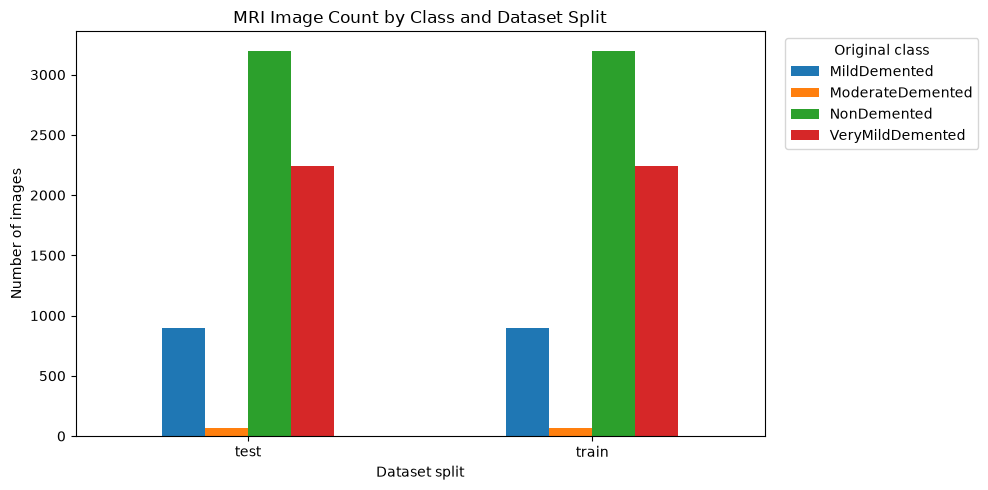

In [5]:
class_counts = (
    metadata.groupby(["split", "class_name"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=CLASS_NAMES, fill_value=0)
)
display(class_counts)

class_counts.plot(kind="bar", figsize=(10, 5))
plt.title("MRI Image Count by Class and Dataset Split")
plt.xlabel("Dataset split")
plt.ylabel("Number of images")
plt.xticks(rotation=0)
plt.legend(title="Original class", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

Sample file: E:\AI\Project\Alzheimer_s Dataset\train\MildDemented\mild.jpg
Original image shape (height, width, channels): (128, 128, 3)
Original image dtype: uint8
Original pixel minimum: 0
Original pixel maximum: 255


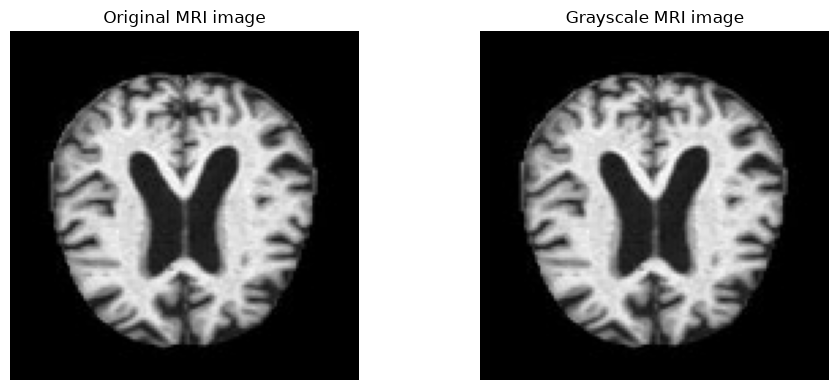

In [6]:
# Numerical and categorical data
# - Categorical metadata: split, class_name, and file_path.
# - Numerical image data: grayscale pixel values. After resizing to 64 × 64, each image has 4,096 pixel features.
# - file_path is an identifier and is not used as a model feature.
# The image dataset has no conventional tabular numeric columns before image loading. 
# We therefore inspect numerical statistics after loading and flattening the images.

# Inspect one readable image to report its dimensions and channels.
sample_image = None
sample_path = None

for record in all_records:
    candidate = cv2.imread(record["file_path"])
    if candidate is not None:
        sample_image = candidate
        sample_path = record["file_path"]
        break

if sample_image is None:
    raise ValueError("No readable images were found. Check the dataset files.")

print("Sample file:", sample_path)
print("Original image shape (height, width, channels):", sample_image.shape)
print("Original image dtype:", sample_image.dtype)
print("Original pixel minimum:", sample_image.min())
print("Original pixel maximum:", sample_image.max())

sample_gray = cv2.cvtColor(sample_image, cv2.COLOR_BGR2GRAY)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(sample_image, cv2.COLOR_BGR2RGB))
plt.title("Original MRI image")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(sample_gray, cmap="gray")
plt.title("Grayscale MRI image")
plt.axis("off")
plt.tight_layout()
plt.show()

In [42]:
# Separate Numerical and Categorical Columns

numerical_columns = metadata.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = metadata.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical metadata columns:")
print(numerical_columns)

print("\nCategorical metadata columns:")
print(categorical_columns)

print("\nImage pixel features:")
print("4096 numerical features per image")

Numerical metadata columns:
[]

Categorical metadata columns:
['split', 'class_name', 'file_path']

Image pixel features:
4096 numerical features per image


In [ ]:

# # Stage B – Handling Missing Values

# ## Objective

# The purpose of this stage is to identify missing or invalid observations and decide how they should be handled before model training.

# ## Missing Value Investigation

# Unlike conventional tabular datasets, the selected dataset consists of MRI image files rather than rows containing individual numerical measurements.

# Therefore, missing values are investigated at two levels:

# 1. Metadata-level missing values.
# 2. Image-level missing or unreadable files.

# The metadata analysis shows that there are no missing values in the split, class_name, and file_path columns.

# The image-loading process is also used to identify corrupted or unreadable MRI files.

# ## Handling Strategy

# A conventional mean or median imputation technique is not appropriate for an entirely missing or corrupted MRI image because reconstructing the original brain image using a statistical value would not be meaningful.

# Instead, unreadable images are excluded from the usable dataset.

# ## Results

# - Unreadable training images: 0
# - Unreadable testing images: 0
# - Missing metadata values: 0

# Since no unreadable images or missing metadata values were detected, no observations needed to be removed or imputed.

# ## Conclusion

# The dataset is complete and all identified MRI image files were successfully loaded. Therefore, no missing-value imputation or image removal was required.


In [7]:
# Stage B – Handling missing values and unreadable files
# A missing or corrupted MRI image cannot be reliably reconstructed by applying a tabular mean or median to the whole image. 
# We therefore attempt to read every image and record failures. 
# Unreadable files are excluded from the usable dataset and their count is reported.

# This is the image-data equivalent of identifying missing observations. 
# No pixel-level mean/median imputation is performed because the dataset is made of complete 
# image files rather than a table with individual missing cells.

def load_split_records(records, image_size=(64, 64)):
    images, labels, paths, failures = [], [], [], []
    for record in records:
        image = cv2.imread(record["file_path"])
        if image is None:
            failures.append(record["file_path"])
            continue

        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        resized = cv2.resize(gray, image_size, interpolation=cv2.INTER_AREA)
        normalized = resized.astype(np.float32) / 255.0

        images.append(normalized)
        labels.append(record["class_name"])
        paths.append(record["file_path"])

    return (
        np.asarray(images, dtype=np.float32),
        np.asarray(labels),
        np.asarray(paths),
        failures
    )

X_train_images, y_train_original, train_paths, train_failures = load_split_records(train_records)
X_test_images, y_test_original, test_paths, test_failures = load_split_records(test_records)

print("Unreadable training files:", len(train_failures))
print("Unreadable testing files:", len(test_failures))
print("Usable training images:", len(X_train_images))
print("Usable testing images:", len(X_test_images))
print("Training image tensor shape:", X_train_images.shape)
print("Testing image tensor shape:", X_test_images.shape)

if len(X_train_images) == 0 or len(X_test_images) == 0:
    raise ValueError("No usable images in train or test split.")

Unreadable training files: 0
Unreadable testing files: 0
Usable training images: 6400
Usable testing images: 6400
Training image tensor shape: (6400, 64, 64)
Testing image tensor shape: (6400, 64, 64)


In [8]:
failure_summary = pd.DataFrame({
    "split": ["train", "test"],
    "unreadable_files": [len(train_failures), len(test_failures)]
})
failure_summary["handling"] = np.where(
    failure_summary["unreadable_files"] > 0,
    "Excluded because the image could not be decoded",
    "No unreadable files detected"
)
display(failure_summary)

,split,unreadable_files,handling
0,train,0,No unreadable files detected
1,test,0,No unreadable files detected


In [ ]:

# # Stage C – Categorical-to-Numerical Encoding

# ## Objective

# Machine learning algorithms require numerical target values for classification. Therefore, the original categorical class labels are converted into numerical values.

# ## Original Categories

# The dataset contains four original categories:

# - MildDemented
# - ModerateDemented
# - NonDemented
# - VeryMildDemented

# For this project, the classification problem is simplified into two categories.

# ## Binary Encoding Strategy

# The following mapping is applied:

# | Original Category | Encoded Value |
# |---|---:|
# | NonDemented | 0 |
# | MildDemented | 1 |
# | ModerateDemented | 1 |
# | VeryMildDemented | 1 |

# Here:

# - 0 represents Non-Demented.
# - 1 represents Demented.

# This is binary target encoding because the objective is to distinguish between non-demented and dementia-labelled MRI images.

# ## Justification

# Binary encoding is selected because the project focuses on binary classification rather than predicting individual dementia severity levels.

# The original class labels are retained separately for reference, while the encoded values are used as the target variable during model training.

# The split and file_path columns are retained only as metadata and are not used as model input features.

# ## Conclusion

# The original four-class dataset is successfully converted into a binary classification dataset, making it suitable for the selected SVM and Quantum Machine Learning models.


In [9]:
# Stage C – Categorical-to-numerical encoding
# The original target has four categories. For this project, the prediction task is binary: Non-Demented versus Demented. 
# We map NonDemented to 0 and all three dementia-labelled categories to 1.

# This is binary target encoding, not ordinal encoding: the values 0 and 1 represent two target classes and 
# do not express a severity ranking. The original four-class labels are retained in y_*_original for traceability.

BINARY_LABEL_MAP = {
    "NonDemented": 0,
    "MildDemented": 1,
    "ModerateDemented": 1,
    "VeryMildDemented": 1
}

unknown_labels = set(np.unique(np.concatenate([y_train_original, y_test_original]))) - set(BINARY_LABEL_MAP)
if unknown_labels:
    raise ValueError(f"Unexpected class labels: {unknown_labels}")

y_train = np.array([BINARY_LABEL_MAP[label] for label in y_train_original], dtype=int)
y_test = np.array([BINARY_LABEL_MAP[label] for label in y_test_original], dtype=int)

print("Encoding map:", BINARY_LABEL_MAP)
print("Training target counts:")
print(pd.Series(y_train).map({0: "Non-Demented", 1: "Demented"}).value_counts())
print("\nTesting target counts:")
print(pd.Series(y_test).map({0: "Non-Demented", 1: "Demented"}).value_counts())

Encoding map: {'NonDemented': 0, 'MildDemented': 1, 'ModerateDemented': 1, 'VeryMildDemented': 1}
Training target counts:
Demented        3200
Non-Demented    3200
Name: count, dtype: int64

Testing target counts:
Demented        3200
Non-Demented    3200
Name: count, dtype: int64


,train,test
0 - Non-Demented,3200,3200
1 - Demented,3200,3200


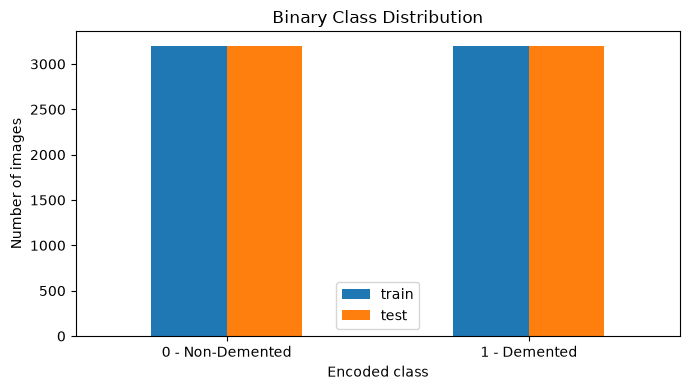

In [10]:
binary_counts = pd.DataFrame({
    "train": pd.Series(y_train).value_counts().reindex([0, 1], fill_value=0),
    "test": pd.Series(y_test).value_counts().reindex([0, 1], fill_value=0)
})
binary_counts.index = ["0 - Non-Demented", "1 - Demented"]
display(binary_counts)

binary_counts.plot(kind="bar", figsize=(7, 4))
plt.title("Binary Class Distribution")
plt.xlabel("Encoded class")
plt.ylabel("Number of images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
# Image representation and pixel-level numerical summary
# Images are converted to grayscale, resized to 64 × 64, normalized to [0, 1], and flattened into 4,096 features per observation. 
# Normalization is a deterministic per-pixel range conversion and does not estimate parameters from the full dataset.

X_train_flat = X_train_images.reshape(len(X_train_images), -1)
X_test_flat = X_test_images.reshape(len(X_test_images), -1)

print("Features per image:", X_train_flat.shape[1])
print("Training matrix:", X_train_flat.shape)
print("Testing matrix:", X_test_flat.shape)
print("Training pixel minimum/maximum:", X_train_flat.min(), X_train_flat.max())

pixel_summary = pd.DataFrame({
    "statistic": ["mean", "std", "min", "25%", "50%", "75%", "max"],
    "training_pixel_value": [
        X_train_flat.mean(),
        X_train_flat.std(),
        np.min(X_train_flat),
        np.percentile(X_train_flat, 25),
        np.percentile(X_train_flat, 50),
        np.percentile(X_train_flat, 75),
        np.max(X_train_flat)
    ]
})
display(pixel_summary)

Features per image: 4096
Training matrix: (6400, 4096)
Testing matrix: (6400, 4096)
Training pixel minimum/maximum: 0.0 0.99215686


,statistic,training_pixel_value
0,mean,0.278918
1,std,0.323009
2,min,0.000000
3,25%,0.000000
4,50%,0.098039
5,75%,0.572549
6,max,0.992157


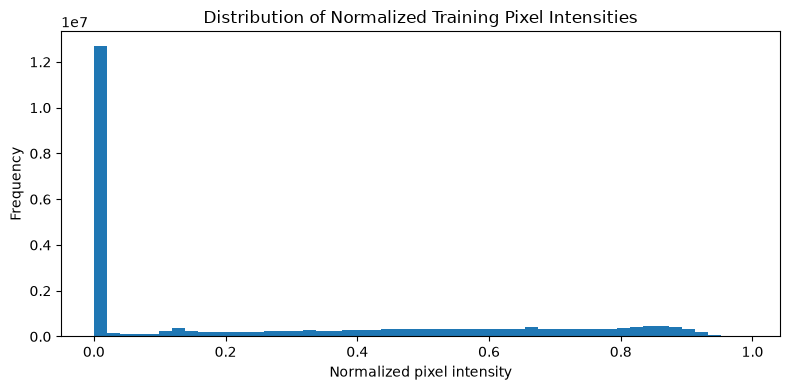

In [12]:
plt.figure(figsize=(8, 4))
plt.hist(X_train_flat.ravel(), bins=50)
plt.title("Distribution of Normalized Training Pixel Intensities")
plt.xlabel("Normalized pixel intensity")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [ ]:

# # Stage D – Binning and Discretization

# ## Objective

# Binning is a preprocessing technique used to convert continuous numerical values into a smaller number of discrete intervals or categories.

# Common binning techniques include:

# - Equal-width binning
# - Equal-frequency binning
# - Domain-based binning

# ## Applicability to the Selected Dataset

# The primary numerical features in this project are grayscale MRI pixel intensities.

# After image normalization, pixel values are represented in the range of 0 to 1.

# These values contain image intensity information that may be useful for identifying patterns in MRI scans.

# ## Decision: Binning Not Applied

# Binning is not applied to the MRI pixel intensities because dividing them into arbitrary intervals could result in the loss of useful intensity information.

# Furthermore, no domain-specific pixel intensity boundaries were provided for this dataset.

# The original normalized pixel values are therefore retained for subsequent preprocessing and model training.

# ## Justification

# Since the input features represent image signals rather than conventional continuous tabular measurements, preserving their intensity variations is more appropriate than applying arbitrary discretization.

# ## Conclusion

# Binning was considered but not applied because it was not suitable for the current image-based feature representation. This decision preserves the original grayscale intensity information.


In [13]:
# Stage D – Binning / discretization
# Decision: Do not bin the MRI pixel intensities in the main modelling pipeline.

# Binning converts continuous grayscale intensities into ranges. 
# Here, the pixel values are already normalized to [0, 1] and represent image intensity patterns. 
# Discretizing every pixel would remove intensity detail that may be useful to the classifiers. 
# There are no independent continuous tabular attributes (such as age or laboratory measurements) for which domain-defined ranges are available.

# Therefore, binning is not appropriate for the current image-feature representation. 
# This is an explicit, dataset-specific justification rather than an omitted step.

binning_decision = pd.DataFrame({
    "candidate feature": ["Normalized MRI pixel intensities"],
    "binning applied": ["No"],
    "reason": [
        "Pixel intensities are image signals; arbitrary bins may discard spatial/intensity detail. "
        "No domain-approved pixel-intensity boundaries were supplied."
    ]
})
display(binning_decision)

,candidate feature,binning applied,reason
0,Normalized MRI pixel intensities,No,Pixel intensities are image signals; arbitrary...


In [ ]:

# # Stage E – Scaling and Transformation

# ## Objective

# Scaling and transformation are used to prepare numerical features for machine learning algorithms by adjusting their ranges and distributions.

# Since MRI images contain pixel intensity values, appropriate scaling is required before applying PCA and the SVM classifier.

# ## 1. Pixel Normalization

# The original grayscale pixel values range from 0 to 255.

# Normalization is applied by dividing every pixel value by 255.

# Formula:

# X_normalized = X / 255

# This converts the pixel intensity range from 0–255 to 0–1.

# ## 2. Standardization

# After flattening each image into 4,096 features, StandardScaler is applied to standardize the numerical features.

# The standardization formula is:

# Z = (X - μ) / σ

# Where:

# - X represents the original feature value.
# - μ represents the training feature mean.
# - σ represents the training feature standard deviation.
# - Z represents the standardized value.

# Standardization is useful because PCA and RBF-based SVM are sensitive to feature scales.

# ## 3. Data Leakage Prevention

# The StandardScaler is fitted only on the training dataset.

# The same learned mean and standard deviation are then used to transform the testing dataset.

# This prevents information from the testing data from influencing the preprocessing parameters.

# ## 4. Skewness and Log Transformation

# Skewness is examined for selected pixel features to understand their distributions.

# The analysis shows that some selected pixel features have different levels of skewness.

# However, a generic logarithmic transformation is not applied because MRI pixel intensities are image signals and may contain zero or near-zero values.

# Applying a log transformation without a suitable domain-specific reason could alter the original image intensity patterns.

# ## Conclusion

# Pixel normalization and standardization are applied to prepare the MRI image features for dimensionality reduction and classification.

# A logarithmic transformation is not applied because it is not justified for the current image-based feature representation.


In [14]:
# Stage E – Scaling and transformation
# The pixel values are first normalized to [0, 1]. 
# Standardization is then applied to the flattened features because PCA and an RBF SVM are sensitive to feature scales.

# Leakage prevention: StandardScaler is fitted only on X_train_flat. 
# The same training mean and standard deviation are used to transform the test set. The test set is never used to fit the scaler.

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_flat)
X_test_scaled = scaler.transform(X_test_flat)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)
print("Mean of first 5 scaled training features:", X_train_scaled.mean(axis=0)[:5])
print("Std of first 5 scaled training features:", X_train_scaled.std(axis=0)[:5])

Scaled training shape: (6400, 4096)
Scaled testing shape: (6400, 4096)
Mean of first 5 scaled training features: [0. 0. 0. 0. 0.]
Std of first 5 scaled training features: [0. 0. 0. 0. 0.]


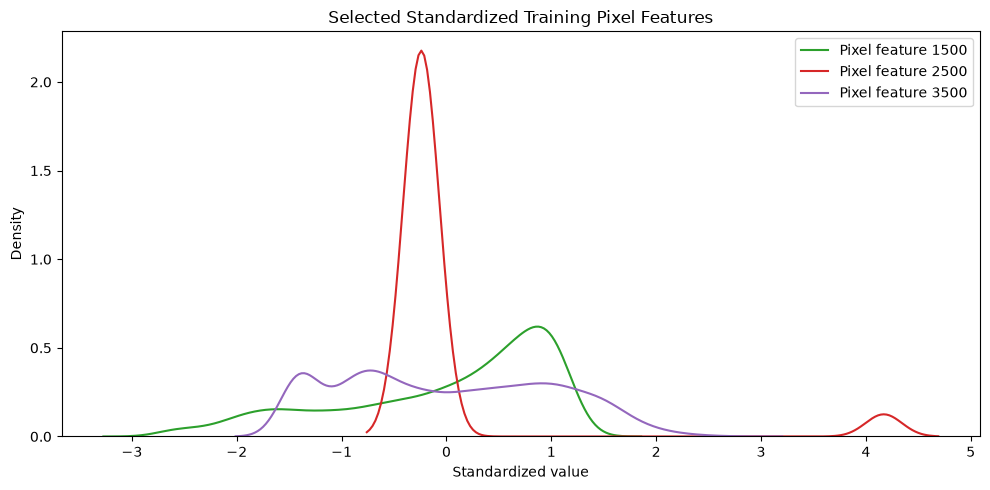

In [15]:
# Compare distributions for a small selection of pixel features.
selected_pixel_features = [0, 500, 1500, 2500, 3500]
plt.figure(figsize=(10, 5))
for feature_index in selected_pixel_features:
    sns.kdeplot(
        X_train_scaled[:, feature_index],
        label=f"Pixel feature {feature_index}",
        fill=False
    )
plt.title("Selected Standardized Training Pixel Features")
plt.xlabel("Standardized value")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

In [46]:
# Skewness / log transformation decision
# A log transformation is commonly useful for strongly right-skewed positive tabular measurements. 
# The current inputs are normalized grayscale pixels, many of which can be zero or near zero, and they are spatially arranged image intensities. 
# Applying a generic log transform to all pixels is not justified without domain evidence and could alter image contrast. 
# We therefore do not apply a log transformation.

# Report skewness for a sample of pixel features as descriptive information.

from scipy.stats import skew

sample_feature_indices = [0, 500, 1500, 2500, 3500]

skewness_values = []

for idx in sample_feature_indices:
    values = X_train_flat[:, idx]

    if np.std(values) == 0:
        skewness_values.append(0.0)
    else:
        skewness_values.append(skew(values))

skewness_report = pd.DataFrame({
    "pixel_feature": sample_feature_indices,
    "training_skewness": skewness_values
})

display(skewness_report)


,pixel_feature,training_skewness
0,0,0.000000
1,500,0.000000
2,1500,-0.844562
3,2500,3.930433
4,3500,0.177916


In [ ]:

# # Stage F – Outlier Detection and Treatment

# ## Objective

# Outlier detection is performed to identify observations that differ significantly from the general distribution of numerical features.

# In this project, the Interquartile Range (IQR) method and boxplots are used to investigate unusual values in selected standardized pixel features and PCA components.

# ## IQR Method

# The Interquartile Range is calculated as:

# IQR = Q3 - Q1

# Where:

# - Q1 represents the first quartile.
# - Q3 represents the third quartile.

# The lower and upper boundaries are calculated as:

# Lower Bound = Q1 - 1.5 × IQR

# Upper Bound = Q3 + 1.5 × IQR

# Observations outside these boundaries are flagged as potential outliers.

# ## Outlier Investigation

# The IQR method is applied to selected standardized pixel features and all four PCA components.

# The PCA outlier analysis identifies the following observations:

# | PCA Component | Outlier Count |
# |---|---:|
# | PC1 | 0 |
# | PC2 | 252 |
# | PC3 | 0 |
# | PC4 | 0 |

# A total of 252 observations, representing approximately 3.94% of the training observations, are flagged as outliers in PC2.

# ## Outlier Treatment Decision

# The detected observations are not automatically removed.

# In MRI image data, unusual pixel intensities or PCA scores may represent genuine variations in image characteristics rather than corrupted data.

# Therefore, valid observations are retained to avoid unnecessary information loss.

# The analysis also treats zero-IQR features carefully because repeated pixel values can produce zero interquartile ranges.

# Only unreadable or corrupted image files would be excluded from the dataset.

# ## Conclusion

# The IQR method successfully identifies potentially unusual observations in the selected numerical features.

# The detected PCA outliers are retained because there is no evidence that they represent invalid MRI images. This approach preserves potentially useful information for model training.


In [17]:
# Stage F – Outlier investigation
# We investigate outliers using the IQR rule on selected standardized pixel features and later on PCA components. 
# An observation outside 1.5 × IQR is flagged for investigation; it is not automatically an error.

# MRI image intensity differences may be genuine. Therefore, we report outlier counts and visualize distributions but do not 
# delete images solely because they are statistically unusual. Corrupted/unreadable files were handled separately in Stage B.

def iqr_outlier_report(matrix, feature_indices, feature_prefix="Feature"):
    rows = []
    for idx in feature_indices:
        values = matrix[:, idx]
        q1 = np.percentile(values, 25)
        q3 = np.percentile(values, 75)
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        count = int(np.sum((values < lower) | (values > upper)))
        rows.append({
            "feature": f"{feature_prefix} {idx}",
            "Q1": q1, "Q3": q3, "IQR": iqr,
            "lower_bound": lower, "upper_bound": upper,
            "outlier_count": count,
            "outlier_percentage": 100 * count / len(values)
        })
    return pd.DataFrame(rows)

pixel_outlier_report = iqr_outlier_report(
    X_train_scaled, selected_pixel_features, "Standardized pixel"
)
display(pixel_outlier_report)

,feature,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percentage
0,Standardized pixel 0,0.000000,0.000000,0.000000,0.000000,0.000000,0,0.0000
1,Standardized pixel 500,0.000000,0.000000,0.000000,0.000000,0.000000,0,0.0000
2,Standardized pixel 1500,-0.642636,0.819070,1.461706,-2.835195,3.011628,0,0.0000
3,Standardized pixel 2500,-0.239795,-0.239795,0.000000,-0.239795,-0.239795,348,5.4375
4,Standardized pixel 3500,-0.843925,0.860380,1.704306,-3.400384,3.416839,0,0.0000


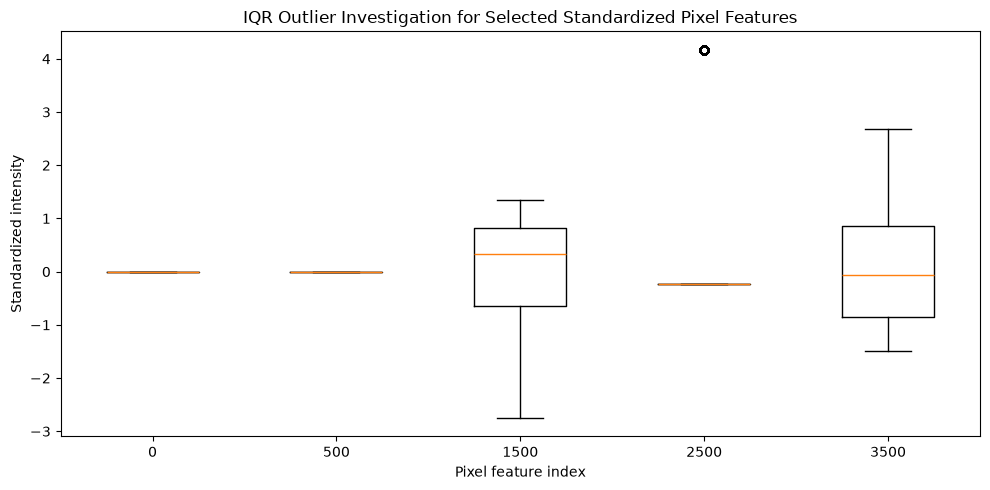

In [20]:

plt.figure(figsize=(10, 5))

plt.boxplot(
    [X_train_scaled[:, idx] for idx in selected_pixel_features],
    tick_labels=[str(idx) for idx in selected_pixel_features],
    showfliers=True
)

plt.title("IQR Outlier Investigation for Selected Standardized Pixel Features")
plt.xlabel("Pixel feature index")
plt.ylabel("Standardized intensity")
plt.tight_layout()
plt.show()


In [ ]:

# # Stage G – Dimensionality Reduction Using PCA

# ## Objective

# Dimensionality reduction is used to reduce the number of input features while retaining important information from the original dataset.

# Each MRI image is resized to 64 × 64 pixels and flattened into a vector containing 4,096 numerical features.

# Processing all 4,096 features directly in a quantum circuit would be computationally expensive.

# Therefore, Principal Component Analysis (PCA) is applied to extract a smaller set of features.

# ## Principal Component Analysis

# PCA is a feature extraction technique that transforms the original correlated features into a new set of uncorrelated variables called principal components.

# These components are arranged according to the amount of variance they explain in the dataset.

# ## PCA Implementation

# In this project:

# - Original features: 4,096
# - Selected principal components: 4
# - Training samples: 6,400
# - Testing samples: 6,400

# The PCA model is fitted only on the standardized training data.

# The same learned transformation is applied to the testing data to prevent data leakage.

# ## Explained Variance

# The four selected components explain a total of 36.48% of the variance in the original standardized training features.

# The individual explained variance ratios are:

# - PC1: 18.90%
# - PC2: 7.78%
# - PC3: 7.07%
# - PC4: 2.74%

# ## Justification for Selecting Four Components

# Four principal components are selected to reduce the feature dimensionality and match the four input qubits used in the Quantum Machine Learning circuit.

# This makes the quantum simulation more manageable while allowing both classical and quantum models to work with the same reduced feature representation.

# ## Conclusion

# PCA reduces the original feature space from 4,096 features to four principal components.

# Although the reduction improves computational efficiency, only 36.48% of the original variance is retained. Therefore, some information is lost during dimensionality reduction, which is an important limitation of the current implementation.


In [21]:
# Stage G – Dimensionality reduction using PCA
# Each 64 × 64 image contains 4,096 flattened pixel features. 
# We use Principal Component Analysis (PCA) to extract four components for the compact SVM/QML experiment.

# PCA is fitted only on the standardized training data. The learned projection is then applied to the test data. 
# Four components are retained to match the four input wires of the quantum circuit and to keep the quantum simulation computationally manageable. 
# The explained variance is reported so the information retained is transparent.

N_PCA_COMPONENTS = 4

pca = PCA(n_components=N_PCA_COMPONENTS, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Features before PCA:", X_train_scaled.shape[1])
print("Features after PCA:", X_train_pca.shape[1])
print("Training PCA shape:", X_train_pca.shape)
print("Testing PCA shape:", X_test_pca.shape)
print("Explained variance ratio:", np.round(pca.explained_variance_ratio_, 4))
print(
    "Total variance explained by 4 components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2), "%"
)

Features before PCA: 4096
Features after PCA: 4
Training PCA shape: (6400, 4)
Testing PCA shape: (6400, 4)
Explained variance ratio: [0.189  0.0778 0.0707 0.0274]
Total variance explained by 4 components: 36.48 %


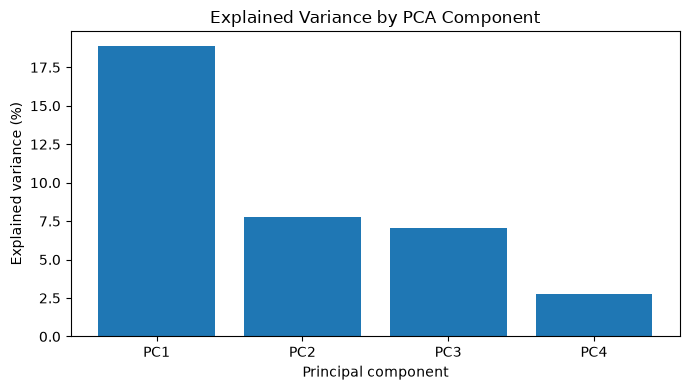

In [22]:
plt.figure(figsize=(7, 4))
plt.bar(
    [f"PC{i+1}" for i in range(N_PCA_COMPONENTS)],
    pca.explained_variance_ratio_ * 100
)
plt.title("Explained Variance by PCA Component")
plt.xlabel("Principal component")
plt.ylabel("Explained variance (%)")
plt.tight_layout()
plt.show()

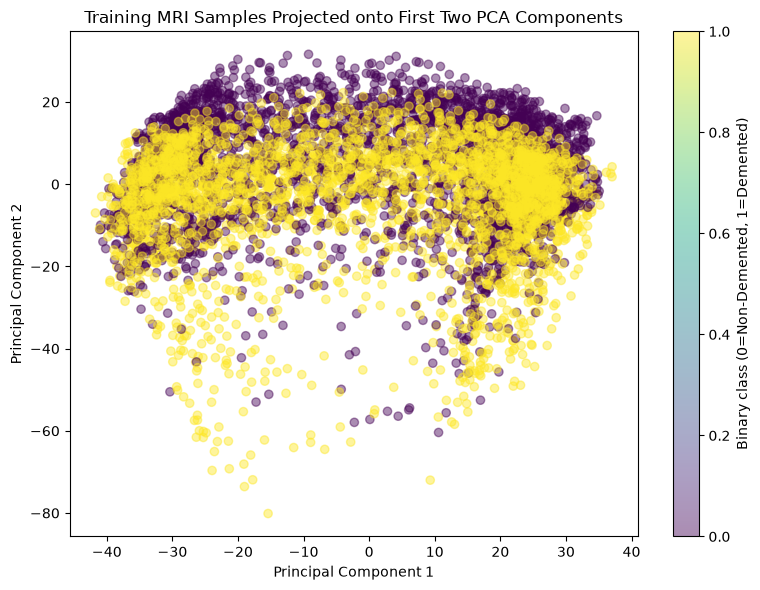

In [23]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_train_pca[:, 0], X_train_pca[:, 1],
    c=y_train, alpha=0.45
)
plt.title("Training MRI Samples Projected onto First Two PCA Components")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Binary class (0=Non-Demented, 1=Demented)")
plt.tight_layout()
plt.show()

,feature,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percentage
0,PCA component 0,-23.598112,21.430845,45.028957,-91.141548,88.974281,0,0.0000
1,PCA component 1,-6.807810,9.760486,16.568296,-31.660254,34.612930,252,3.9375
2,PCA component 2,-12.185745,12.074832,24.260578,-48.576614,48.465702,0,0.0000
3,PCA component 3,-7.135621,7.051457,14.187078,-28.416237,28.332073,0,0.0000


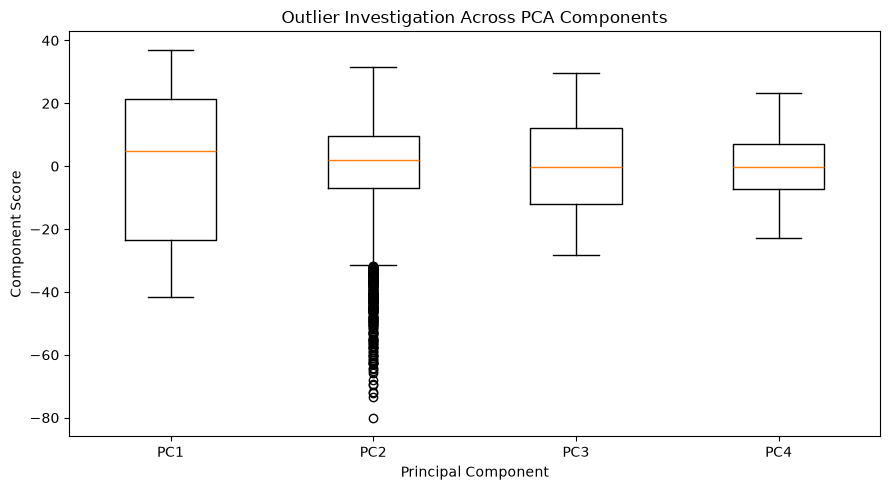

In [25]:

pca_outlier_report = iqr_outlier_report(
    X_train_pca,
    list(range(N_PCA_COMPONENTS)),
    "PCA component"
)

display(pca_outlier_report)

plt.figure(figsize=(9, 5))

plt.boxplot(
    [X_train_pca[:, i] for i in range(N_PCA_COMPONENTS)],
    tick_labels=[f"PC{i+1}" for i in range(N_PCA_COMPONENTS)],
    showfliers=True
)

plt.title("Outlier Investigation Across PCA Components")
plt.xlabel("Principal Component")
plt.ylabel("Component Score")
plt.tight_layout()
plt.show()


In [ ]:

# # Stage H – Model Training and Evaluation

# ## Objective

# The final preprocessing stage involves training machine learning models using the processed MRI image features and evaluating their classification performance.

# The dataset already contains separate training and testing folders. This predefined split is preserved throughout the project.

# All learned preprocessing operations, including StandardScaler and PCA, are fitted exclusively on the training dataset and then applied to the testing dataset.

# ## 1. Classical Machine Learning – Support Vector Machine

# A Support Vector Machine (SVM) classifier with an RBF kernel is implemented as the classical baseline model.

# SVM attempts to identify an optimal decision boundary that separates the two classes.

# The RBF kernel allows the model to learn nonlinear decision boundaries.

# The model is trained using the four PCA components and evaluated using the complete held-out testing dataset.

# ## 2. Quantum Machine Learning

# A Quantum Machine Learning classifier is implemented using PennyLane.

# The circuit contains four qubits corresponding to the four PCA features.

# The quantum circuit uses:

# - Angle Embedding to encode the PCA features.
# - Trainable RY rotation gates to adjust the quantum states.
# - CNOT gates to introduce entanglement between qubits.
# - Pauli-Z expectation measurement to produce the model output.
# - Adam optimizer to update the trainable circuit parameters.

# The quantum model is trained using a balanced subset containing 200 samples from each class, giving a total of 400 training images.

# The complete testing dataset is used for final evaluation.

# ## 3. Balanced-Subset SVM

# An additional SVM model is trained using exactly the same 400 training samples selected for the Quantum ML model.

# This provides a more controlled comparison between the subset-trained classical and quantum models.

# ## 4. Evaluation Metrics

# The models are evaluated using the following metrics:

# - Accuracy: Measures the overall proportion of correct predictions.
# - Precision: Measures how many predicted positive cases are actually positive.
# - Recall: Measures how many actual positive cases are correctly identified.
# - F1-score: Represents the harmonic mean of precision and recall.

# The positive class is defined as Demented (label 1).

# ## 5. Model Comparison

# All three models are evaluated using the same 6,400-image testing dataset.

# The results are:

# | Model | Accuracy | Precision | Recall | F1-score |
# |---|---:|---:|---:|---:|
# | SVM (Full Training) | 67.53% | 63.43% | 82.78% | 71.83% |
# | SVM (Balanced Subset) | 65.78% | 62.35% | 79.69% | 69.96% |
# | Quantum ML | 61.89% | 63.90% | 54.66% | 58.92% |

# ## Observations

# The full-training SVM achieves the highest accuracy, recall, and F1-score among the three models.

# The balanced-subset SVM performs slightly below the full-training SVM, showing the effect of reducing the number of training samples.

# The Quantum ML model achieves a lower accuracy and recall than both SVM models in the current experiment.

# However, the quantum implementation demonstrates how a small variational quantum circuit can be integrated into an image-classification pipeline.

# ## Conclusion

# The experimental results show that the classical SVM model performs better than the current Quantum ML implementation.

# The comparison also highlights the importance of training sample size, feature representation, and model architecture in classification performance.


In [26]:
# Stage H – Classical model training: SVM
# We train an RBF-kernel Support Vector Machine using the four PCA features. 
# The training/test split was already provided by the dataset and was established before fitting the scaler or PCA. 
# The SVM is fitted on training PCA features and evaluated once on the held-out test set.

svm_model = SVC(kernel="rbf", class_weight="balanced", random_state=RANDOM_STATE)
svm_model.fit(X_train_pca, y_train)

y_pred_svm = svm_model.predict(X_test_pca)

def calculate_metrics(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1 Score": f1_score(y_true, y_pred, zero_division=0)
    }

svm_results = calculate_metrics(y_test, y_pred_svm, "SVM")
display(pd.DataFrame([svm_results]))
print(classification_report(
    y_test, y_pred_svm,
    labels=[0, 1],
    target_names=["Non-Demented", "Demented"],
    zero_division=0
))

,Model,Accuracy,Precision,Recall,F1 Score
0,SVM,0.675312,0.634339,0.827812,0.718275


              precision    recall  f1-score   support

Non-Demented       0.75      0.52      0.62      3200
    Demented       0.63      0.83      0.72      3200

    accuracy                           0.68      6400
   macro avg       0.69      0.68      0.67      6400
weighted avg       0.69      0.68      0.67      6400



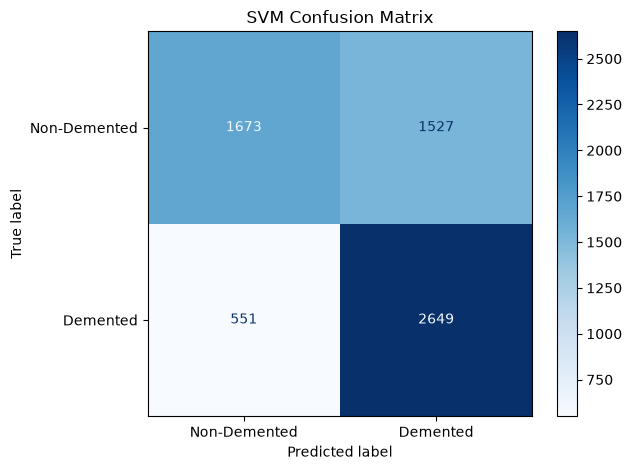

In [27]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_svm,
    display_labels=["Non-Demented", "Demented"],
    cmap="Blues",
    values_format="d"
)
plt.title("SVM Confusion Matrix")
plt.tight_layout()
plt.show()

In [28]:
# Quantum Machine Learning model using PennyLane
# The QML circuit uses four qubits because PCA produces four features. 
# The PCA features are mapped to rotation angles using a min-max transformation fitted on the training PCA data only. 
# AngleEmbedding encodes the features, trainable RY rotations provide adjustable parameters, and CNOT gates create entanglement.

# Runtime note: Quantum circuit simulation can be slow. The settings below limit the number of training examples per class and epochs. 
# These settings are experimental controls, not a change to the held-out test set used for final evaluation.

# Optional dependency. Install in a separate notebook cell if needed:
# %pip install pennylane

try:
    import pennylane as qml
    print("PennyLane version:", qml.__version__)
except ImportError as error:
    raise ImportError(
        "PennyLane is required for the QML section. Install it using %pip install pennylane"
    ) from error

PennyLane version: 0.45.1


In [29]:
# Fit the angle range using training PCA features only.
pca_min = X_train_pca.min(axis=0)
pca_max = X_train_pca.max(axis=0)
pca_range = np.where((pca_max - pca_min) == 0, 1, pca_max - pca_min)

X_train_quantum = ((X_train_pca - pca_min) / pca_range) * np.pi
X_test_quantum = ((X_test_pca - pca_min) / pca_range) * np.pi

print("Quantum training shape:", X_train_quantum.shape)
print("Quantum testing shape:", X_test_quantum.shape)
print("Training angle range:", X_train_quantum.min(), X_train_quantum.max())

Quantum training shape: (6400, 4)
Quantum testing shape: (6400, 4)
Training angle range: 0.0 3.1415927


In [30]:
n_qubits = 4
n_layers = 2

dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev, interface="autograd")
def quantum_circuit(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(n_qubits), rotation="Y")

    for layer in range(n_layers):
        for wire in range(n_qubits):
            qml.RY(weights[layer, wire], wires=wire)
        for wire in range(n_qubits - 1):
            qml.CNOT(wires=[wire, wire + 1])

    return qml.expval(qml.PauliZ(0))

print("Quantum circuit created with", n_qubits, "qubits.")

Quantum circuit created with 4 qubits.


In [31]:
# Prepare a balanced QML training subset
# To keep simulation practical, we sample at most a specified number of examples from each class in the training split. 
# The test set is not sampled or used during training. 
# If the training split is imbalanced, this creates a balanced training subset for the QML experiment; 
# the final metrics still reflect the full held-out test set.

QML_MAX_PER_CLASS = 200  # Increase if runtime permits.
QML_EPOCHS = 20
QML_BATCH_SIZE = 32

def balanced_indices(y, max_per_class, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    selected = []
    for class_label in np.unique(y):
        class_indices = np.where(y == class_label)[0]
        take = min(max_per_class, len(class_indices))
        selected.extend(rng.choice(class_indices, size=take, replace=False))
    rng.shuffle(selected)
    return np.asarray(selected, dtype=int)

qml_train_indices = balanced_indices(y_train, QML_MAX_PER_CLASS)
X_q_train = X_train_quantum[qml_train_indices]
y_q_train = y_train[qml_train_indices]

# Use the entire held-out test set for fair comparison.
X_q_test = X_test_quantum
y_q_test = y_test

print("QML training subset:", X_q_train.shape)
print("QML test set:", X_q_test.shape)
print("QML training class counts:", pd.Series(y_q_train).value_counts().to_dict())

QML training subset: (400, 4)
QML test set: (6400, 4)
QML training class counts: {1: 200, 0: 200}


In [43]:
# SVM trained on the same subset as Quantum ML

svm_subset_model = SVC(
    kernel="rbf",
    class_weight="balanced",
    random_state=RANDOM_STATE
)

svm_subset_model.fit(
    X_train_pca[qml_train_indices],
    y_train[qml_train_indices]
)

y_pred_svm_subset = svm_subset_model.predict(X_test_pca)

svm_subset_results = calculate_metrics(
    y_test,
    y_pred_svm_subset,
    "SVM (Balanced Subset)"
)

print("SVM Performance on Balanced Training Subset")
display(pd.DataFrame([svm_subset_results]))

SVM Performance on Balanced Training Subset


,Model,Accuracy,Precision,Recall,F1 Score
0,SVM (Balanced Subset),0.657813,0.623472,0.796875,0.699588


In [32]:
qml_weights = qml.numpy.random.normal(
    loc=0.0, scale=0.1,
    size=(n_layers, n_qubits),
    requires_grad=True
)

optimizer = qml.AdamOptimizer(stepsize=0.01)

def quantum_loss(weights, X_batch, y_batch):
    predictions = qml.math.stack([
        quantum_circuit(x, weights) for x in X_batch
    ])
    targets = 2 * y_batch - 1  # map labels 0/1 to -1/+1
    return qml.numpy.mean((predictions - targets) ** 2)

print("Initial quantum weights shape:", qml_weights.shape)

Initial quantum weights shape: (2, 4)


In [33]:
loss_history = []

for epoch in range(QML_EPOCHS):
    permutation = np.random.permutation(len(X_q_train))
    epoch_losses = []

    for start in range(0, len(permutation), QML_BATCH_SIZE):
        batch_indices = permutation[start:start + QML_BATCH_SIZE]
        X_batch = X_q_train[batch_indices]
        y_batch = y_q_train[batch_indices]

        qml_weights, batch_loss = optimizer.step_and_cost(
            lambda weights: quantum_loss(weights, X_batch, y_batch),
            qml_weights
        )
        epoch_losses.append(float(batch_loss))

    mean_epoch_loss = float(np.mean(epoch_losses))
    loss_history.append(mean_epoch_loss)
    print(f"Epoch {epoch + 1}/{QML_EPOCHS} - Loss: {mean_epoch_loss:.4f}")

Epoch 1/20 - Loss: 1.5366
Epoch 2/20 - Loss: 1.5201
Epoch 3/20 - Loss: 1.5218
Epoch 4/20 - Loss: 1.4806
Epoch 5/20 - Loss: 1.3731
Epoch 6/20 - Loss: 1.3053
Epoch 7/20 - Loss: 1.1802
Epoch 8/20 - Loss: 1.0879
Epoch 9/20 - Loss: 1.0089
Epoch 10/20 - Loss: 0.9531
Epoch 11/20 - Loss: 0.9208
Epoch 12/20 - Loss: 0.9144
Epoch 13/20 - Loss: 0.9027
Epoch 14/20 - Loss: 0.8895
Epoch 15/20 - Loss: 0.8877
Epoch 16/20 - Loss: 0.8913
Epoch 17/20 - Loss: 0.8861
Epoch 18/20 - Loss: 0.8871
Epoch 19/20 - Loss: 0.8828
Epoch 20/20 - Loss: 0.8913


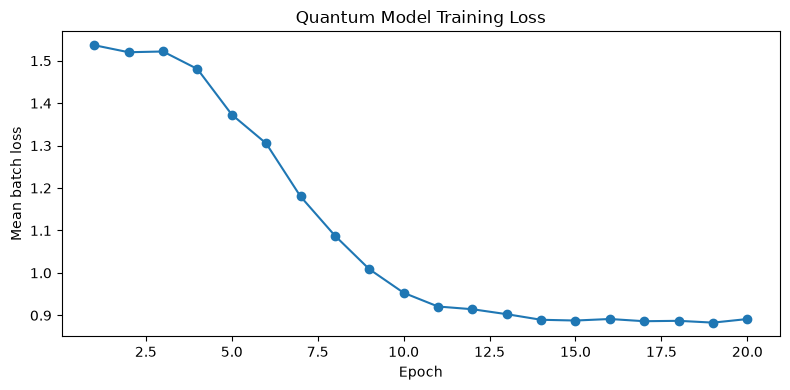

In [34]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(loss_history) + 1), loss_history, marker="o")
plt.title("Quantum Model Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean batch loss")
plt.tight_layout()
plt.show()

In [35]:
def quantum_predict_class(x, weights):
    output = float(quantum_circuit(x, weights))
    return 1 if output >= 0 else 0

y_pred_qml = np.array([
    quantum_predict_class(x, qml_weights) for x in X_q_test
], dtype=int)

qml_results = calculate_metrics(y_test, y_pred_qml, "Quantum ML")
display(pd.DataFrame([qml_results]))
print(classification_report(
    y_test, y_pred_qml,
    labels=[0, 1],
    target_names=["Non-Demented", "Demented"],
    zero_division=0
))

,Model,Accuracy,Precision,Recall,F1 Score
0,Quantum ML,0.618906,0.639021,0.546562,0.589186


              precision    recall  f1-score   support

Non-Demented       0.60      0.69      0.64      3200
    Demented       0.64      0.55      0.59      3200

    accuracy                           0.62      6400
   macro avg       0.62      0.62      0.62      6400
weighted avg       0.62      0.62      0.62      6400



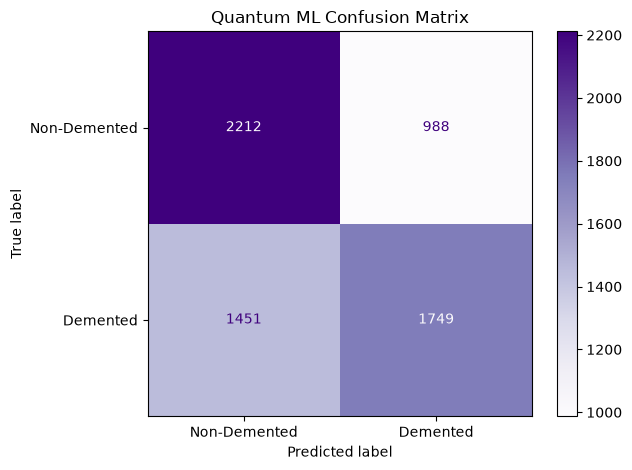

In [36]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_qml,
    display_labels=["Non-Demented", "Demented"],
    cmap="Purples",
    values_format="d"
)
plt.title("Quantum ML Confusion Matrix")
plt.tight_layout()
plt.show()

In [44]:
# Model comparison and observations
# Both models are evaluated on the same complete held-out test set. Accuracy, precision, recall and F1-score are reported. 
# For this binary task, class 1 (Demented) is treated as the positive class by scikit-learn's precision, recall and F1 calculations.



# Model Performance Comparison

results = pd.DataFrame([
    calculate_metrics(y_test, y_pred_svm, "SVM (Full Training Set)"),
    calculate_metrics(y_test, y_pred_svm_subset, "SVM (Balanced Subset)"),
    calculate_metrics(y_test, y_pred_qml, "Quantum ML")
])

# Convert metrics into percentages
metric_columns = [
    "Accuracy", "Precision", "Recall", "F1 Score"
]

for column in metric_columns:
    results[column] = (results[column] * 100).round(2)

print("MODEL PERFORMANCE COMPARISON")
print("============================")

display(results)



MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,SVM (Full Training Set),67.53,63.43,82.78,71.83
1,SVM (Balanced Subset),65.78,62.35,79.69,69.96
2,Quantum ML,61.89,63.90,54.66,58.92


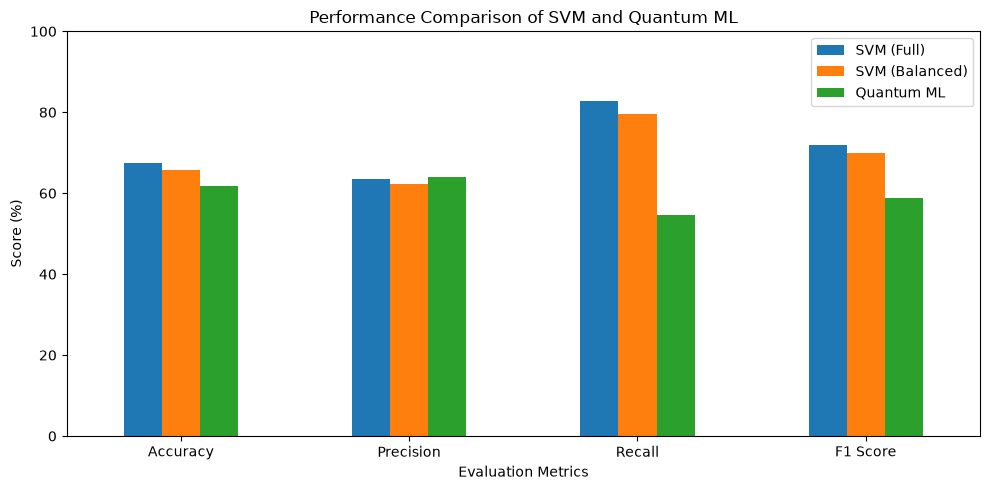

In [45]:

# Compare all three models

metric_names = ["Accuracy", "Precision", "Recall", "F1 Score"]

svm_full_values = [
    svm_results[m] * 100 for m in metric_names
]

svm_subset_values = [
    svm_subset_results[m] * 100 for m in metric_names
]

qml_values = [
    qml_results[m] * 100 for m in metric_names
]

comparison = pd.DataFrame({
    "SVM (Full)": svm_full_values,
    "SVM (Balanced)": svm_subset_values,
    "Quantum ML": qml_values
}, index=metric_names)

comparison.plot(kind="bar", figsize=(10, 5))

plt.title("Performance Comparison of SVM and Quantum ML")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()


In [47]:
print("Final dataset and feature summary")
print("----------------------------------")
print("Usable training images:", len(X_train_images))
print("Usable testing images:", len(X_test_images))
print("Original image size:", "64 x 64 grayscale")
print("Features before PCA:", X_train_scaled.shape[1])
print("Features after PCA:", X_train_pca.shape[1])
print("PCA variance retained:", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")
print("Unreadable train files:", len(train_failures))
print("Unreadable test files:", len(test_failures))
display(results)

Final dataset and feature summary
----------------------------------
Usable training images: 6400
Usable testing images: 6400
Original image size: 64 x 64 grayscale
Features before PCA: 4096
Features after PCA: 4
PCA variance retained: 36.48 %
Unreadable train files: 0
Unreadable test files: 0


,Model,Accuracy,Precision,Recall,F1 Score
0,SVM (Full Training Set),67.53,63.43,82.78,71.83
1,SVM (Balanced Subset),65.78,62.35,79.69,69.96
2,Quantum ML,61.89,63.90,54.66,58.92


In [ ]:
# Challenges, limitations and future improvements
# 1. Binary label merging: Three dementia severity categories are merged into one class. 
#     This simplifies the task but removes severity-level information.
# 2. Image-level split: The supplied folders provide train/test separation, but patient-level grouping is not documented. 
#    If multiple images belong to the same patient, patient-level splitting would be preferable to avoid related-image leakage.
# 3. PCA information loss: Four components provide a compact representation but may discard substantial image information. 
#    Report the measured explained variance.
# 4. QML simulation cost: A state-vector simulator can be computationally expensive. 
#    The QML training subset and epoch count are configurable.
# 5. Medical limitation: The dataset and experiment are educational. External validation, patient-level evaluation, 
#    clinical review and bias assessment would be required before any medical use.
# 6. Future work: Explore more PCA components, multi-class classification, patient-level splits, 
#    CNN-based feature extraction and hybrid quantum-classical architectures.

In [ ]:

# # Conclusion and Future Scope

# ## Conclusion

# This project explored the application of classical Machine Learning and Quantum Machine Learning techniques for Alzheimer's disease classification using MRI images.

# The project began with an exploration of the MRI dataset, which contained 12,800 images divided into four original categories. These categories were converted into a binary classification problem consisting of Non-Demented and Demented classes.

# Several preprocessing techniques were implemented to prepare the images for model training. These included grayscale conversion, resizing, pixel normalization, feature flattening, standardization, missing-value investigation, categorical encoding, and outlier detection.

# Principal Component Analysis (PCA) was applied to reduce the original 4,096 image features to four principal components, retaining 36.48% of the total variance.

# Two primary classification approaches were investigated: a classical Support Vector Machine with an RBF kernel and a four-qubit Quantum Machine Learning model implemented using PennyLane.

# An additional SVM model was trained on the same balanced subset used by the Quantum ML model to provide a more controlled performance comparison.

# The experimental results showed that the full-training SVM achieved the highest accuracy of 67.53% and an F1-score of 71.83%. The balanced-subset SVM achieved 65.78% accuracy, while the Quantum ML model achieved 61.89% accuracy.

# These findings indicate that the classical SVM performed better than the current Quantum ML implementation on the selected dataset and experimental configuration.

# Although the Quantum ML model did not outperform the classical baseline, the project successfully demonstrates the integration of quantum computing concepts with an image-based machine learning pipeline.

# Overall, the project provided practical experience in image preprocessing, feature extraction, dimensionality reduction, classical classification, quantum circuit implementation, and model evaluation.

# ## Limitations

# The current implementation has several limitations:

# 1. The original four categories were merged into two classes, resulting in the loss of dementia severity information.
# 2. PCA retains only 36.48% of the original variance, meaning that some image information is lost.
# 3. The Quantum ML model uses only 400 training samples because of computational limitations.
# 4. Patient-level separation between training and testing images has not been independently verified.
# 5. The models have not been externally validated on an independent clinical dataset.

# ## Future Scope

# The project can be improved in several ways:

# - Experiment with a larger number of PCA components to retain more information.
# - Explore different quantum circuit architectures and additional quantum layers.
# - Experiment with different optimizers and circuit configurations.
# - Investigate hybrid quantum-classical machine learning architectures.
# - Explore CNN-based feature extraction for MRI images.
# - Use patient-level dataset splitting and independent validation.
# - Investigate multiclass classification to distinguish between different dementia severity levels.
# - Evaluate the models on larger and more diverse MRI datasets.

# ## Final Takeaway

# The project demonstrates the potential of combining image processing, classical machine learning, and quantum machine learning for Alzheimer's-related MRI image classification.

# The results establish a classical SVM baseline and provide an experimental foundation for further exploration of Quantum Machine Learning in medical image analysis.

# **Note:** This project is an academic research experiment and is not a clinically validated diagnostic system. Its predictions should not be used for medical diagnosis or treatment decisions.
